# ClickHouse — практика МГТУ Баумана

**Кластер:** 2 шарда × 2 реплики

**Что делаем:**
1. Подключаемся к кластеру
2. Смотрим устройство кластера
3. Создаём таблицы (локальные + Distributed)
4. Вставляем данные и смотрим как они распределяются
5. Исследуем MergeTree — Parts, сжатие, индексы
6. Пишем аналитические запросы
7. Создаём MaterializedView
8. Смотрим system таблицы


Рабочая копия для `homework_cluster`. Исходный файл сохранён в корне. Выполняйте ячейки по порядку; повторный INSERT добавляет данные повторно.


## 0. Установка зависимостей

In [1]:
# Зависимости уже установлены в Docker-образе.
# Для локального Python: %pip install clickhouse-connect pandas matplotlib seaborn


In [2]:
import os
import clickhouse_connect
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import random
import time

# Docker: ch11; local Python: localhost.
client = clickhouse_connect.get_client(
    host=os.getenv('CLICKHOUSE_HOST', 'localhost'),
    port=int(os.getenv('CLICKHOUSE_PORT', '8123')),
    username=os.getenv('CLICKHOUSE_USER', 'default'),
    password=os.getenv('CLICKHOUSE_PASSWORD', 'homework'),
)
print('ClickHouse version:', client.query('SELECT version()').first_row[0])


ClickHouse version: 25.8.33.6


## 1. Исследуем кластер

Смотрим что за кластер у нас поднят

In [3]:
# Смотрим все шарды и реплики кластера
df = client.query_df("""
SELECT
    cluster,
    shard_num,
    replica_num,
    host_name,
    port,
    is_local
FROM system.clusters
WHERE cluster = 'homework_cluster'
ORDER BY shard_num, replica_num
""")
print(df.to_string(index=False))

         cluster  shard_num  replica_num host_name  port  is_local
homework_cluster          1            1      ch11  9000         1
homework_cluster          1            2      ch12  9000         0
homework_cluster          2            1      ch21  9000         0
homework_cluster          2            2      ch22  9000         0


In [4]:
# Смотрим макросы текущей ноды
df = client.query_df("""
SELECT macro, substitution
FROM system.macros
""")
print("Макросы текущей ноды:")
print(df.to_string(index=False))

Макросы текущей ноды:
  macro substitution
replica         ch11
  shard           01


In [5]:
df = client.query_df("""
SELECT *
FROM clusterAllReplicas('homework_cluster', system.tables)
""")
print("Все таблицы:")
print(df.to_string(index=False))

Все таблицы:


IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [6]:
client.query_df("SELECT hostName() AS host, version() AS version")


,host,version
0,ch11,25.8.33.6


In [7]:
# Смотрим все ноды кластера и их hostname
df = client.query_df("""
SELECT *
FROM clusterAllReplicas('homework_cluster', system.one)
""")
print("Все ноды кластера:")
print(df.to_string(index=False))

Все ноды кластера:
 dummy
     0
     0
     0
     0


## 2. Создаём таблицы

Паттерн в ClickHouse:
- **Локальная таблица** (ReplicatedMergeTree) — реальные данные, на каждой ноде своя
- **Distributed таблица** — виртуальная, роутер запросов по всем шардам

In [8]:
# Создаём базу данных на всём кластере
client.command("""
CREATE DATABASE IF NOT EXISTS dwh ON CLUSTER homework_cluster
""")
print("База данных dwh создана")

База данных dwh создана


In [9]:
# Создаём локальную таблицу на всех нодах
# {shard} и {replica} заменяются из macros.xml каждой ноды
client.command("""
CREATE TABLE IF NOT EXISTS dwh.events_local ON CLUSTER homework_cluster
(
    event_date      Date,
    event_time      DateTime,
    user_id         UInt64,
    event_type      LowCardinality(String),
    platform        LowCardinality(String),
    country         LowCardinality(String),
    value           Float64,
    session_id      String
)
ENGINE = ReplicatedMergeTree(
    '/clickhouse/tables/{shard}/dwh/events_local',
    '{replica}'
)
PARTITION BY toYYYYMM(event_date)
ORDER BY (event_type, user_id, event_time)
""")
print("Локальная таблица events_local создана на всех нодах")

Локальная таблица events_local создана на всех нодах


In [10]:
# Создаём Distributed таблицу — точка входа для запросов
client.command("""
CREATE TABLE IF NOT EXISTS dwh.events ON CLUSTER homework_cluster
AS dwh.events_local
ENGINE = Distributed(
    'homework_cluster',      -- кластер
    'dwh',              -- база данных
    'events_local',     -- локальная таблица
    rand()              -- sharding key — равномерное распределение
)
""")
print("Distributed таблица events создана")

Distributed таблица events создана


## 3. Вставляем данные и смотрим распределение

Генерируем синтетические события пользователей

In [11]:
# Генерируем тестовые данные
random.seed(42)

event_types = ['click', 'view', 'purchase', 'add_to_cart', 'search', 'logout']
platforms   = ['ios', 'android', 'web']
countries   = ['RU', 'US', 'DE', 'FR', 'BR', 'CN', 'IN']

rows = []
base_date = datetime(2024, 1, 1)

for i in range(1_000_000):  # 1 миллион событий
    event_time = base_date + timedelta(
        days=random.randint(0, 89),
        hours=random.randint(0, 23),
        minutes=random.randint(0, 59)
    )
    rows.append((
        event_time.date(),
        event_time,
        random.randint(1, 100_000),
        random.choice(event_types),
        random.choice(platforms),
        random.choice(countries),
        round(random.uniform(0, 1000), 2),
        f'sess_{random.randint(1, 500_000)}'
    ))

print(f"Сгенерировано {len(rows):,} строк")
print(f"Пример строки: {rows[0]}")

Сгенерировано 1,000,000 строк
Пример строки: (datetime.date(2024, 3, 22), datetime.datetime(2024, 3, 22, 3, 1), 97197, 'purchase', 'ios', 'US', 139.54, 'sess_53737')


In [11]:
# Генерируем тестовые данные
random.seed(42)

event_types = ['click', 'view', 'purchase', 'add_to_cart', 'search', 'logout']
platforms   = ['ios', 'android', 'web']
countries   = ['RU', 'US', 'DE', 'FR', 'BR', 'CN', 'IN']

rows = []
base_date = datetime(2024, 1, 1)

for i in range(1_000_000):  # 1 миллион событий
    event_time = base_date + timedelta(
        days=random.randint(0, 89),
        hours=random.randint(0, 23),
        minutes=random.randint(0, 59)
    )
    rows.append((
        event_time.date(),
        event_time,
        random.randint(1, 100_000),
        random.choice(event_types),
        random.choice(platforms),
        random.choice(countries),
        round(random.uniform(0, 1000), 2),
        f'sess_{random.randint(1, 500_000)}'
    ))

print(f"Сгенерировано {len(rows):,} строк")
print(f"Пример строки: {rows[0]}")

Сгенерировано 1,000,000 строк
Пример строки: (datetime.date(2024, 3, 22), datetime.datetime(2024, 3, 22, 3, 1), 97197, 'purchase', 'ios', 'US', 139.54, 'sess_53737')


In [12]:
# Вставляем батчем в Distributed таблицу
# CH сам распределит данные по шардам через rand()
start = time.time()

client.insert(
    'dwh.events',
    rows,
    column_names=[
        'event_date', 'event_time', 'user_id', 'event_type',
        'platform', 'country', 'value', 'session_id'
    ]
)

elapsed = time.time() - start
print(f"Вставлено {len(rows):,} строк за {elapsed:.2f} сек")
print(f"Скорость: {len(rows)/elapsed:,.0f} строк/сек")

Вставлено 1,000,000 строк за 1.62 сек
Скорость: 618,522 строк/сек


In [13]:
# Смотрим как данные распределились по шардам
df = client.query_df("""
SELECT
    hostName()                              AS host,
    count()                                 AS parts,
    formatReadableQuantity(sum(rows))       AS total_rows,
    formatReadableSize(sum(bytes_on_disk))  AS size_on_disk
FROM clusterAllReplicas('homework_cluster', system.parts)
WHERE active
  AND database = 'dwh'
  AND table = 'events_local'
GROUP BY host
ORDER BY host
""")
print("Распределение данных по шардам:")
print(df.to_string(index=False))

Распределение данных по шардам:
host  parts      total_rows size_on_disk
ch11      3 500.19 thousand    10.11 MiB
ch12      3 500.19 thousand    10.11 MiB
ch21      3 499.81 thousand    10.10 MiB
ch22      3 499.81 thousand    10.10 MiB


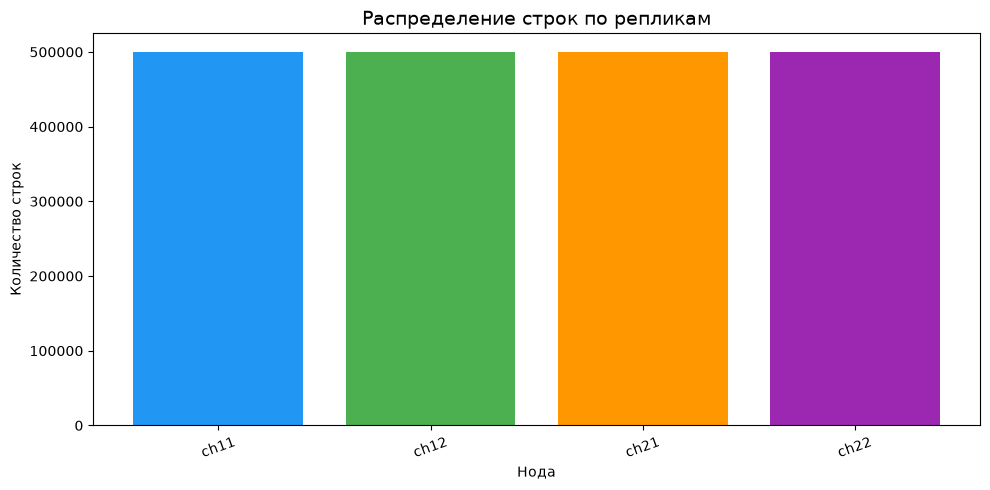

In [14]:
# Визуализируем распределение
df_vis = client.query_df("""
SELECT
    hostName()  AS host,
    sum(rows)   AS total_rows
FROM clusterAllReplicas('homework_cluster', system.parts)
WHERE active
  AND database = 'dwh'
  AND table = 'events_local'
GROUP BY host
ORDER BY host
""")

plt.figure(figsize=(10, 5))
plt.bar(df_vis['host'], df_vis['total_rows'], color=['#2196F3', '#4CAF50', '#FF9800', '#9C27B0'])
plt.title('Распределение строк по репликам', fontsize=14)
plt.xlabel('Нода')
plt.ylabel('Количество строк')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [15]:
df = client.query_df("""
SELECT count(*) from dwh.events_local
""")
print(df.to_string(index=False))

 count()
  500195


In [16]:
df = client.query_df("""
SELECT count(*) from dwh.events
""")
print(df.to_string(index=False))

 count()
 1000000


In [17]:
df = client.query_df("""
SELECT count(*) from clusterAllReplicas('homework_cluster', 'dwh.events_local')
""")
print(df.to_string(index=False))

 count()
 2000000


## 4. Исследуем MergeTree — Parts и сжатие

In [18]:
# Смотрим Parts — куски данных на диске
df = client.query_df("""
SELECT
    name                                            AS part_name,
    partition,
    rows,
    formatReadableSize(bytes_on_disk)               AS size,
    formatReadableSize(data_uncompressed_bytes)     AS uncompressed,
    round(data_uncompressed_bytes /
          data_compressed_bytes, 2)                AS compression_ratio,
    level,
    modification_time
FROM system.parts
WHERE active
  AND database = 'dwh'
  AND table = 'events_local'
ORDER BY modification_time DESC
LIMIT 20
""")
print("Parts на текущей ноде:")
print(df.to_string(index=False))

Parts на текущей ноде:
   part_name partition   rows     size uncompressed  compression_ratio  level   modification_time
202401_0_0_0    202401 172424 3.48 MiB     6.05 MiB               1.74      0 2026-10-09 17:34:51
202402_0_0_0    202402 160872 3.25 MiB     5.65 MiB               1.74      0 2026-10-09 17:34:51
202403_0_0_0    202403 166899 3.37 MiB     5.86 MiB               1.74      0 2026-10-09 17:34:51


In [19]:
# Сжатие по колонкам — кто сжимается лучше всего?
df = client.query_df("""
SELECT
    column,
    formatReadableSize(sum(data_compressed_bytes))      AS compressed,
    formatReadableSize(sum(data_uncompressed_bytes))    AS uncompressed,
    round(sum(data_uncompressed_bytes) /
          sum(data_compressed_bytes), 2)               AS compression_ratio
FROM system.parts_columns
WHERE active
  AND database = 'dwh'
  AND table = 'events_local'
GROUP BY column
ORDER BY compression_ratio DESC
""")
print("Сжатие по колонкам:")
print(df.to_string(index=False))

Сжатие по колонкам:
    column compressed uncompressed  compression_ratio
   user_id  10.10 MiB    17.55 MiB               1.74
     value  10.10 MiB    17.55 MiB               1.74
  platform  10.10 MiB    17.55 MiB               1.74
   country  10.10 MiB    17.55 MiB               1.74
session_id  10.10 MiB    17.55 MiB               1.74
event_time  10.10 MiB    17.55 MiB               1.74
event_type  10.10 MiB    17.55 MiB               1.74
event_date  10.10 MiB    17.55 MiB               1.74


In [20]:
# Ждём пока CH сделает merge (объединит мелкие Parts)
print("Ждём merge...")
time.sleep(10)

# Смотрим активные merge
df = client.query_df("""
SELECT
    hostName()                          AS host,
    database,
    table,
    elapsed,
    round(progress * 100, 1)            AS progress_pct,
    formatReadableSize(total_size_bytes_compressed) AS size
FROM clusterAllReplicas('homework_cluster', system.merges)
""")
if len(df) > 0:
    print("Активные merge:")
    print(df.to_string(index=False))
else:
    print("Merge завершены")

Ждём merge...
Merge завершены


## 5. Аналитические запросы

Смотрим насколько быстро ClickHouse обрабатывает аналитику

In [21]:
# Запрос 1: события по типу
start = time.time()
df = client.query_df("""
SELECT
    event_type,
    count()             AS events,
    uniq(user_id)       AS unique_users,
    round(avg(value), 2) AS avg_value,
    round(sum(value), 2) AS total_value
FROM dwh.events
GROUP BY event_type
ORDER BY events DESC
""")
elapsed = time.time() - start
print(f"Запрос выполнен за {elapsed:.3f} сек на {df['events'].sum():,} строках")
print(df.to_string(index=False))

Запрос выполнен за 0.130 сек на 1,000,000 строках
 event_type  events  unique_users  avg_value  total_value
     search  166966         81334     498.94  83306203.09
     logout  166771         81130     500.48  83464950.02
      click  166747         81328     499.21  83241735.65
       view  166662         81344     499.30  83214086.58
add_to_cart  166470         81436     499.94  83224530.04
   purchase  166384         81361     499.55  83117094.42


Запрос выполнен за 0.087 сек


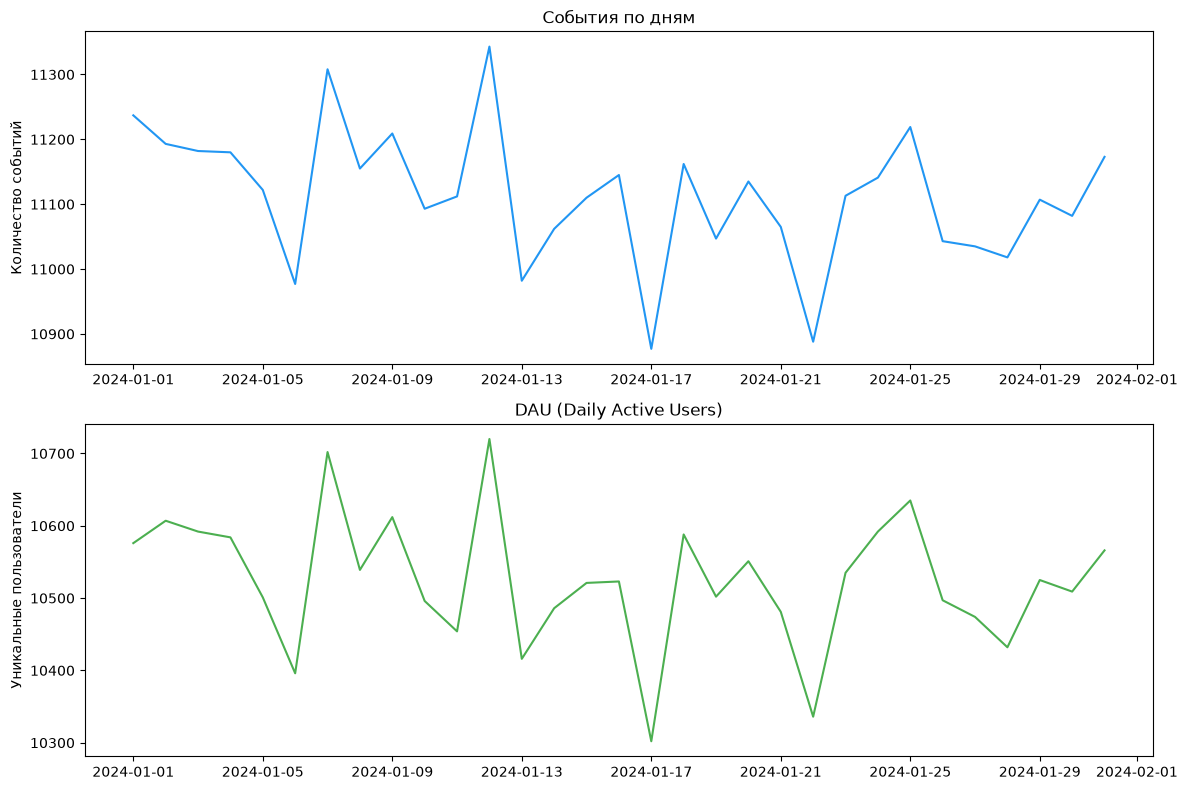

In [22]:
# Запрос 2: динамика по дням
start = time.time()
df = client.query_df("""
SELECT
    event_date,
    count()         AS events,
    uniq(user_id)   AS dau
FROM dwh.events
WHERE event_date BETWEEN '2024-01-01' AND '2024-01-31'
GROUP BY event_date
ORDER BY event_date
""")
elapsed = time.time() - start
print(f"Запрос выполнен за {elapsed:.3f} сек")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))
ax1.plot(df['event_date'], df['events'], color='#2196F3')
ax1.set_title('События по дням')
ax1.set_ylabel('Количество событий')

ax2.plot(df['event_date'], df['dau'], color='#4CAF50')
ax2.set_title('DAU (Daily Active Users)')
ax2.set_ylabel('Уникальные пользователи')

plt.tight_layout()
plt.show()

In [23]:
# Запрос 3: воронка событий
df = client.query_df("""
SELECT
    platform,
    country,
    countIf(event_type = 'view')        AS views,
    countIf(event_type = 'click')       AS clicks,
    countIf(event_type = 'add_to_cart') AS add_to_cart,
    countIf(event_type = 'purchase')    AS purchases,
    round(countIf(event_type = 'purchase') /
          countIf(event_type = 'view') * 100, 2) AS conversion_pct
FROM dwh.events
GROUP BY platform, country
ORDER BY conversion_pct DESC
LIMIT 15
""")
print("Воронка по платформе и стране:")
print(df.to_string(index=False))

Воронка по платформе и стране:
platform country  views  clicks  add_to_cart  purchases  conversion_pct
 android      CN   7851    7896         8016       8022          102.18
 android      RU   7854    8021         7846       7971          101.49
     ios      DE   7900    7801         8047       8007          101.35
     web      US   7935    7842         7887       8014          101.00
     ios      US   7877    7910         8173       7939          100.79
     web      CN   7861    7915         7898       7912          100.65
 android      FR   8007    7823         7849       8044          100.46
     ios      RU   7783    8137         7961       7816          100.42
 android      IN   7954    7836         7961       7977          100.29
     web      BR   7934    7936         7890       7954          100.25
     ios      FR   7941    7777         7868       7955          100.18
     ios      IN   8011    7902         8053       7989           99.73
 android      DE   7901    7998  

## 6. Partition pruning — как CH пропускает ненужные данные

In [24]:
# Без фильтра по дате — читаем все партиции
result = client.query("""
SELECT count()
FROM dwh.events
SETTINGS send_progress_in_http_headers = 1
""")

# С фильтром по дате — читаем только нужную партицию
# Смотрим через query_log сколько данных было прочитано
client.command("SYSTEM FLUSH LOGS")

df = client.query_df("""
SELECT
    query,
    read_rows,
    read_bytes,
    formatReadableSize(read_bytes)  AS read_size,
    query_duration_ms               AS duration_ms
FROM system.query_log
WHERE type = 'QueryFinish'
  AND query LIKE '%dwh.events%'
  AND event_time > now() - INTERVAL 5 MINUTE
ORDER BY event_time DESC
LIMIT 5
""")
print("Последние запросы к events:")
print(df[['read_rows', 'read_size', 'duration_ms']].to_string(index=False))

Последние запросы к events:
 read_rows read_size  duration_ms
         2   32.00 B           13
   1000000  2.86 MiB           59
    344515  3.29 MiB           84
   1000000 16.21 MiB          127
         4   64.00 B            7


## 7. MaterializedView — агрегация в реальном времени

In [25]:
# Создаём таблицу для агрегатов
client.command("""
CREATE TABLE IF NOT EXISTS dwh.events_hourly_local ON CLUSTER homework_cluster
(
    hour            DateTime,
    event_type      LowCardinality(String),
    platform        LowCardinality(String),
    events_count    UInt64,
    unique_users    AggregateFunction(uniq, UInt64),
    total_value     Float64
)
ENGINE = ReplicatedAggregatingMergeTree(
    '/clickhouse/tables/{shard}/dwh/events_hourly_local',
    '{replica}'
)
PARTITION BY toYYYYMM(hour)
ORDER BY (hour, event_type, platform)
""")

client.command("""
CREATE TABLE IF NOT EXISTS dwh.events_hourly ON CLUSTER homework_cluster
AS dwh.events_hourly_local
ENGINE = Distributed('homework_cluster', 'dwh', 'events_hourly_local', rand())
""")

print("Таблица events_hourly создана")

Таблица events_hourly создана


In [26]:
# Создаём MaterializedView — будет срабатывать при каждом INSERT в events_local
client.command("""
CREATE MATERIALIZED VIEW IF NOT EXISTS dwh.events_hourly_mv ON CLUSTER homework_cluster
TO dwh.events_hourly_local
AS SELECT
    toStartOfHour(event_time)   AS hour,
    event_type,
    platform,
    count()                     AS events_count,
    uniqState(user_id)          AS unique_users,
    sum(value)                  AS total_value
FROM dwh.events_local
GROUP BY hour, event_type, platform
""")
print("MaterializedView events_hourly_mv создан")

MaterializedView events_hourly_mv создан


In [27]:
# Вставляем новые данные — MV сработает автоматически
new_rows = []
base_date = datetime(2024, 4, 1)
for i in range(100_000):
    event_time = base_date + timedelta(
        hours=random.randint(0, 23),
        minutes=random.randint(0, 59)
    )
    new_rows.append((
        event_time.date(), event_time,
        random.randint(1, 100_000),
        random.choice(event_types),
        random.choice(platforms),
        random.choice(countries),
        round(random.uniform(0, 1000), 2),
        f'sess_{random.randint(1, 500_000)}'
    ))

client.insert('dwh.events', new_rows,
    column_names=['event_date', 'event_time', 'user_id', 'event_type',
                  'platform', 'country', 'value', 'session_id'])
print(f"Вставлено {len(new_rows):,} новых строк")

Вставлено 100,000 новых строк


In [28]:
# Запрашиваем агрегаты — мгновенно, данные уже посчитаны
start = time.time()
df = client.query_df("""
SELECT
    hour,
    event_type,
    platform,
    sum(events_count)               AS events,
    uniqMerge(unique_users)         AS unique_users,
    round(sum(total_value), 2)      AS total_value
FROM dwh.events_hourly
WHERE hour >= '2024-04-01'
GROUP BY hour, event_type, platform
ORDER BY hour, events DESC
LIMIT 20
""")
elapsed = time.time() - start
print(f"Агрегаты получены за {elapsed:.3f} сек (данные уже посчитаны MV)")
print(df.to_string(index=False))

Агрегаты получены за 0.039 сек (данные уже посчитаны MV)
               hour  event_type platform  events  unique_users  total_value
2024-04-01 00:00:00      search      web     275           275    131268.58
2024-04-01 00:00:00      search  android     264           263    129850.10
2024-04-01 00:00:00       click      web     259           259    132302.89
2024-04-01 00:00:00 add_to_cart      ios     243           243    115586.75
2024-04-01 00:00:00      search      ios     241           240    124454.34
2024-04-01 00:00:00       click  android     236           235    115051.15
2024-04-01 00:00:00 add_to_cart  android     236           236    119645.01
2024-04-01 00:00:00      logout      ios     227           227    119639.99
2024-04-01 00:00:00    purchase  android     226           226    115438.10
2024-04-01 00:00:00      logout      web     225           225    108615.69
2024-04-01 00:00:00        view  android     225           225    114371.64
2024-04-01 00:00:00       click

## 8. Мониторинг кластера через system таблицы

In [29]:
# Распределение данных по шардам
df = client.query_df("""
SELECT
    hostName()                              AS host,
    count()                                 AS parts,
    formatReadableQuantity(sum(rows))       AS rows,
    formatReadableSize(sum(bytes_on_disk))  AS size
FROM clusterAllReplicas('homework_cluster', system.parts)
WHERE active AND database = 'dwh'
GROUP BY host
ORDER BY host
""")
print("Распределение данных по кластеру:")
print(df.to_string(index=False))

Распределение данных по кластеру:
host  parts            rows      size
ch11      5 550.71 thousand 11.21 MiB
ch12      5 550.71 thousand 11.21 MiB
ch21      5 550.16 thousand 11.21 MiB
ch22      5 550.16 thousand 11.21 MiB


In [30]:
# Состояние репликации
df = client.query_df("""
SELECT
    hostName()          AS host,
    database,
    table,
    is_leader,
    is_readonly,
    total_replicas,
    active_replicas,
    queue_size
FROM clusterAllReplicas('homework_cluster', system.replicas)
WHERE database = 'dwh'
ORDER BY host, table
""")
print("Состояние репликации:")
print(df.to_string(index=False))

Состояние репликации:
host database               table  is_leader  is_readonly  total_replicas  active_replicas  queue_size
ch11      dwh events_hourly_local          1            0               2                2           0
ch11      dwh        events_local          1            0               2                2           0
ch12      dwh events_hourly_local          1            0               2                2           0
ch12      dwh        events_local          1            0               2                2           0
ch21      dwh events_hourly_local          1            0               2                2           0
ch21      dwh        events_local          1            0               2                2           0
ch22      dwh events_hourly_local          1            0               2                2           0
ch22      dwh        events_local          1            0               2                2           0


In [31]:
# Метрики фоновых пулов
df = client.query_df("""
SELECT
    hostName()  AS host,
    metric,
    value
FROM clusterAllReplicas('homework_cluster', system.metrics)
WHERE metric LIKE '%Background%'
ORDER BY host, metric
""")
print("Фоновые пулы:")
print(df.to_string(index=False))

Фоновые пулы:
host                                      metric  value
ch11       BackgroundBufferFlushSchedulePoolSize     16
ch11       BackgroundBufferFlushSchedulePoolTask      0
ch11                    BackgroundCommonPoolSize      8
ch11                    BackgroundCommonPoolTask      0
ch11       BackgroundDistributedSchedulePoolSize     16
ch11       BackgroundDistributedSchedulePoolTask      0
ch11                   BackgroundFetchesPoolSize     16
ch11                   BackgroundFetchesPoolTask      0
ch11        BackgroundMergesAndMutationsPoolSize     32
ch11        BackgroundMergesAndMutationsPoolTask      0
ch11     BackgroundMessageBrokerSchedulePoolSize     16
ch11     BackgroundMessageBrokerSchedulePoolTask      0
ch11                      BackgroundMovePoolSize      8
ch11                      BackgroundMovePoolTask      0
ch11                  BackgroundSchedulePoolSize    512
ch11                  BackgroundSchedulePoolTask      1
ch11                        KafkaB